# Анализ данных, обучение моделей и метрики

Ноутбук дает рабочий цикл эксперимента: первичный EDA, подготовка train/validation, обучение baseline-моделей, сравнение метрик и разбор ошибок. Обучение выполняется только на train, выбор модели — только на validation. Official test читается только при аудите пересечений и не участвует в обучении или подборе.

Меняйте параметры в ячейке конфигурации и запускайте ноутбук сверху вниз. Каждый запуск сохраняет сводные результаты, отчеты по классам, матрицы ошибок, сериализованные модели и записи MLflow в проекте.

## 1. Подключение проекта и библиотек

In [1]:
from pathlib import Path
import json
import sys
import time
import joblib
import mlflow
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
import sklearn

def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / 'configs' / 'baseline.json').exists() and (candidate / 'src').is_dir():
            return candidate
    raise FileNotFoundError('Не найдена папка проекта с configs/baseline.json')

ROOT = find_project_root()
sys.path.insert(0, str(ROOT / 'src'))
from models.baseline import build_models
CONFIG_PATH = ROOT / 'configs' / 'baseline.json'
DATA_DIR = ROOT / 'data' / 'processed'
OUT_DIR = ROOT / 'experiments' / 'baseline'
MODEL_DIR = ROOT / 'work' / 'notebook_models'
OUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print(f'Проект: {ROOT}')
print(f'Python: {sys.version.split()[0]} | scikit-learn: {sklearn.__version__}')

C:\Users\maks5\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Проект: C:\Users\maks5\Documents\Codex\2026-11-13\x20
Python: 3.14.3 | scikit-learn: 1.9.1


## 2. Первичный анализ датасета (EDA)

Ноутбук проверит исходные файлы по SHA-256, покажет пропуски, баланс классов, длины запросов, повторы и пересечения формулировок. Если исходных файлов нет, EDA покажет доступную подготовленную выборку.

{
  "splits": {
    "train": {
      "rows": 10003,
      "classes": 77,
      "missing": {
        "text": 0,
        "category": 0
      },
      "class_min": 35,
      "class_max": 187,
      "median_chars": 47.0,
      "p95_chars": 151.89999999999964,
      "duplicates": {
        "exact_duplicate_rows": 0,
        "exact_duplicate_values": 0,
        "normalized_duplicate_rows": 8,
        "normalized_duplicate_values": 4
      }
    },
    "test": {
      "rows": 3080,
      "classes": 77,
      "missing": {
        "text": 0,
        "category": 0
      },
      "class_min": 40,
      "class_max": 40,
      "median_chars": 45.0,
      "p95_chars": 124.0,
      "duplicates": {
        "exact_duplicate_rows": 0,
        "exact_duplicate_values": 0,
        "normalized_duplicate_rows": 2,
        "normalized_duplicate_values": 1
      }
    }
  },
  "cross_split": {
    "exact_text_overlap_unique": 0,
    "normalized_overlap_unique": 7,
    "normalized_overlapping_train_rows": 7,
 

,split,rows,classes,missing,median_chars,normalized_duplicate_rows
0,train,10003,77,0,47.0,8
1,test,3080,77,0,45.0,2


,exact_text_overlap_unique,normalized_overlap_unique,normalized_overlapping_train_rows,normalized_overlapping_test_rows,label_conflicts_on_normalized_overlap
0,0,7,7,7,0


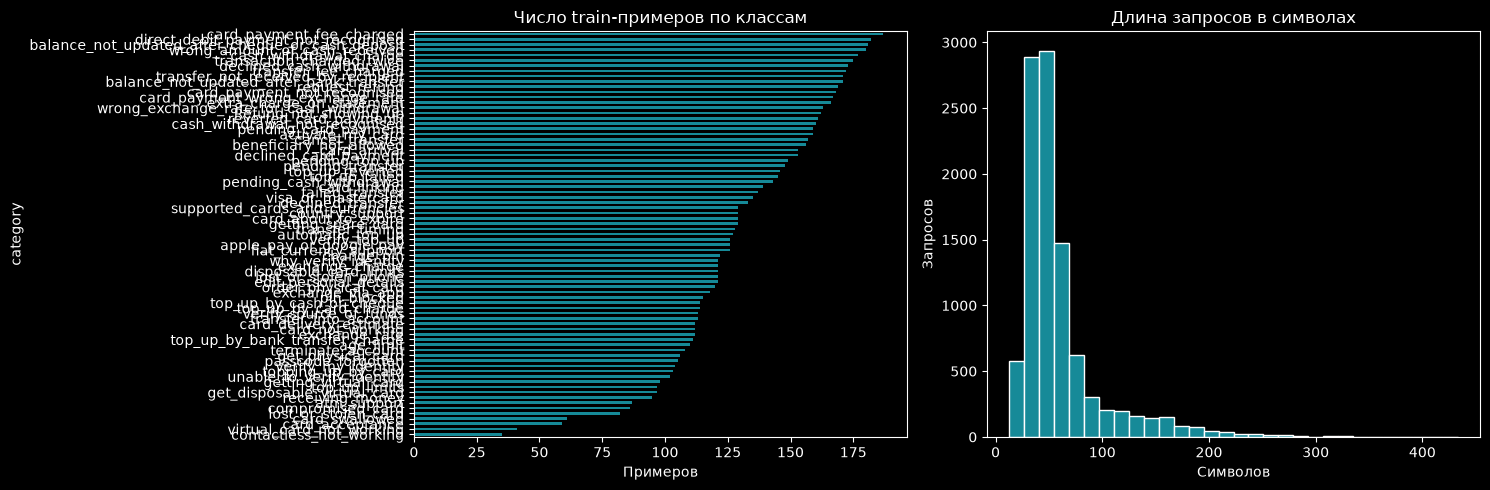

,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


In [2]:
import runpy
raw_train = ROOT / 'data' / 'raw' / 'train.csv'
raw_test = ROOT / 'data' / 'raw' / 'test.csv'
if raw_train.exists() and raw_test.exists():
    eda_module = runpy.run_path(str(ROOT / 'src' / 'data' / 'eda.py'))
    eda_module['main']()
    eda_train_df = pd.read_csv(raw_train)
    eda_summary = json.loads((ROOT / 'reports' / 'eda_summary.json').read_text(encoding='utf-8'))
    display(pd.DataFrame([{'split': name, 'rows': values['rows'], 'classes': values['n_classes'], 'missing': sum(values['missing_by_column'].values()), 'median_chars': values['text_length']['characters']['0.5'], 'normalized_duplicate_rows': values['duplicates']['normalized_duplicate_rows']} for name, values in eda_summary['splits'].items()]))
    display(pd.DataFrame([eda_summary['cross_split']]))
else:
    processed_train_path = ROOT / 'data' / 'processed' / 'train.csv'
    if not processed_train_path.exists():
        raise FileNotFoundError('Для EDA добавьте BANKING77 train.csv и test.csv в data/raw.')
    print('Исходные CSV отсутствуют; строю обзор подготовленной train-выборки.')
    eda_train_df = pd.read_csv(processed_train_path)

class_counts = eda_train_df['category'].value_counts().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
class_counts.plot(kind='barh', ax=axes[0], color='#168A98', title='Число train-примеров по классам')
axes[0].set_xlabel('Примеров')
text_lengths = eda_train_df['text'].astype(str).str.len()
axes[1].hist(text_lengths, bins=30, color='#168A98', edgecolor='white')
axes[1].set_title('Длина запросов в символах')
axes[1].set_xlabel('Символов')
axes[1].set_ylabel('Запросов')
fig.tight_layout()
plt.show()
display(eda_train_df.head())

## 3. Проверка конфигурации и подготовка выборок

Если сырые файлы уже находятся в `data/raw/`, эта ячейка повторно создаст воспроизводимое разбиение. Очистка исключает дубликаты и совпадения с official test по нормализованному тексту; метки test не участвуют в обучении и выборе модели.

In [3]:
config = json.loads(CONFIG_PATH.read_text(encoding='utf-8-sig'))
raw_train = ROOT / 'data' / 'raw' / 'train.csv'
raw_test = ROOT / 'data' / 'raw' / 'test.csv'
if raw_train.exists() and raw_test.exists():
    import runpy
    split_module = runpy.run_path(str(ROOT / 'src' / 'data' / 'prepare_splits.py'))
    split_module['main']()
else:
    print('Исходные CSV не найдены; использую уже подготовленные data/processed файлы.')

train_path = DATA_DIR / 'train.csv'
validation_path = DATA_DIR / 'validation.csv'
if not train_path.exists() or not validation_path.exists():
    raise FileNotFoundError('Не найдены train.csv/validation.csv. Положите исходные CSV в data/raw и повторите ячейку.')
train_df = pd.read_csv(train_path)
validation_df = pd.read_csv(validation_path)
required_columns = {'text', 'category'}
assert required_columns.issubset(train_df.columns) and required_columns.issubset(validation_df.columns)
assert train_df[list(required_columns)].notna().all().all()
assert validation_df[list(required_columns)].notna().all().all()
assert set(train_df['category']) == set(validation_df['category'])

display(pd.DataFrame({'split': ['train', 'validation'], 'rows': [len(train_df), len(validation_df)], 'classes': [train_df.category.nunique(), validation_df.category.nunique()]}))
display(train_df.head())

{
  "removed_internal_duplicates": 4,
  "removed_test_overlaps_from_train": 7,
  "clean_train": 9992,
  "train": 7993,
  "validation": 1999,
  "classes": 77,
  "train_support_min_max": [
    28,
    149
  ],
  "validation_support_min_max": [
    7,
    38
  ],
  "official_test_unchanged": true,
  "manifest": "C:\\Users\\maks5\\Documents\\Codex\\2026-11-13\\x20\\experiments\\baseline\\split_manifest.json"
}


,split,rows,classes
0,train,7993,77
1,validation,1999,77


,text,category
0,How do I see my updated balance after I make a...,balance_not_updated_after_cheque_or_cash_deposit
1,What currencies can I have?,fiat_currency_support
2,I don't remember my login code,passcode_forgotten
3,Is there anything to do because my phone was s...,lost_or_stolen_phone
4,There's a direct debit payment that I don't re...,direct_debit_payment_not_recognised


## 4. Настройки эксперимента

Параметры ниже можно изменить перед повторным обучением. Модельный pipeline включает TF-IDF внутри fit, чтобы словарь строился только по train.

In [4]:
experiment_name = config['tracking']['experiment']
tracking_db = ROOT / config['tracking']['database']
mlflow.set_tracking_uri(f"sqlite:///{tracking_db.as_posix()}")
mlflow.set_experiment(experiment_name)

X_train = train_df['text'].astype(str)
y_train = train_df['category'].astype(str)
X_val = validation_df['text'].astype(str)
y_val = validation_df['category'].astype(str)
labels = sorted(y_train.unique())
models = build_models(config)
print(f'Эксперимент MLflow: {experiment_name}')
print(f'Моделей к обучению: {len(models)} | train: {len(X_train):,} | validation: {len(X_val):,}')
display(pd.DataFrame([{'model': name, 'estimator': repr(model)[:180]} for name, model in models.items()]))

Эксперимент MLflow: banking77-classical-baselines
Моделей к обучению: 4 | train: 7,993 | validation: 1,999


,model,estimator
0,majority,DummyClassifier(strategy='most_frequent')
1,tfidf_logistic_regression,"Pipeline(steps=[('tfidf',\n Tf..."
2,tfidf_linear_svm,"Pipeline(steps=[('tfidf',\n Tf..."
3,tfidf_multinomial_nb,"Pipeline(steps=[('tfidf',\n Tf..."


## 5. Обучение и оценка

Для каждой модели рассчитываются accuracy, macro/weighted precision, recall и F1. Macro F1 усредняет качество по классам и используется для сортировки. Модели и артефакты сохраняются локально, а параметры и метрики логируются в MLflow.

In [5]:
results = []
predictions = {}
reports = {}
fitted_models = {}
for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    y_pred = np.asarray(model.predict(X_val))
    predictions[name] = y_pred
    fitted_models[name] = model
    report = classification_report(y_val, y_pred, labels=labels, output_dict=True, zero_division=0)
    reports[name] = pd.DataFrame(report).T
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(y_val, y_pred, labels=labels, average='macro', zero_division=0)
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(y_val, y_pred, labels=labels, average='weighted', zero_division=0)
    metrics = {'accuracy': accuracy_score(y_val, y_pred), 'macro_precision': macro_p, 'macro_recall': macro_r, 'macro_f1': macro_f1, 'weighted_precision': weighted_p, 'weighted_recall': weighted_r, 'weighted_f1': weighted_f1, 'fit_seconds': fit_seconds}
    model_path = MODEL_DIR / f'{name}.joblib'
    joblib.dump(model, model_path)
    reports[name].to_csv(OUT_DIR / f'{name}_classification_report.csv', index_label='label')
    confusion = pd.DataFrame(confusion_matrix(y_val, y_pred, labels=labels), index=labels, columns=labels)
    confusion.to_csv(OUT_DIR / f'{name}_confusion_matrix.csv', index_label='true_label')
    with mlflow.start_run(run_name=name) as run:
        mlflow.log_params({'model': name, 'sklearn_version': sklearn.__version__, 'train_rows': len(X_train), 'validation_rows': len(X_val), 'tfidf_ngram_range': str(config['tfidf']['ngram_range']), 'tfidf_min_df': config['tfidf']['min_df']})
        mlflow.set_tags({'dataset': 'BANKING77', 'evaluation_split': 'validation', 'workflow': 'jupyter_notebook'})
        mlflow.log_metrics({key: float(value) for key, value in metrics.items()})
        mlflow.log_artifact(str(model_path), artifact_path='serialized_model')
        mlflow.log_artifact(str(OUT_DIR / f'{name}_classification_report.csv'), artifact_path='evaluation')
        metrics['mlflow_run_id'] = run.info.run_id
    results.append({'model': name, **{key: float(value) for key, value in metrics.items() if key != 'mlflow_run_id'}, 'mlflow_run_id': metrics['mlflow_run_id']})

results_df = pd.DataFrame(results).sort_values('macro_f1', ascending=False).reset_index(drop=True)
results_df.to_csv(OUT_DIR / 'notebook_results.csv', index=False)
display(results_df.style.format(precision=4).highlight_max(subset=['accuracy', 'macro_f1', 'weighted_f1'], color='#d7f2df'))
print(f'Сводка записана: {OUT_DIR / "notebook_results.csv"}')

2026/11/13 18:44:41 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/11/13 18:44:41 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,fit_seconds,mlflow_run_id
0,tfidf_linear_svm,0.8789,0.8870,0.8776,0.8795,0.8836,0.8789,0.8786,0.5796,0c6e4d371f464358937b98c9ead6e34b
1,tfidf_logistic_regression,0.8469,0.8627,0.8339,0.8395,0.8553,0.8469,0.8454,11.8038,0c0c2a334c39442eb8774a0dde6c04ef
2,tfidf_multinomial_nb,0.7989,0.8032,0.7610,0.7632,0.8119,0.7989,0.7901,0.2142,337b0fc528ad4b08938a95a66e4f3d98
3,majority,0.0190,0.0002,0.0130,0.0005,0.0004,0.0190,0.0007,0.0045,1da226faf82e40369e2a63648f1d20a3


Сводка записана: C:\Users\maks5\Documents\Codex\2026-11-13\x20\experiments\baseline\notebook_results.csv


## 6. Разбор лучшей модели и ошибок

Выбор лучшей модели выполняется по Macro F1 на validation. После изменения конфигурации или данных снова выполните ячейку обучения перед этим разделом.

In [6]:
best_name = results_df.iloc[0]['model']
best_model = fitted_models[best_name]
best_pred = predictions[best_name]
print(f'Лучшая модель по validation Macro F1: {best_name} ({results_df.iloc[0]["macro_f1"]:.4f})')
display(reports[best_name].loc[labels].sort_values('f1-score').head(15))

mistakes = validation_df.loc[y_val.to_numpy() != best_pred].copy()
mistakes['predicted_category'] = best_pred[y_val.to_numpy() != best_pred]
mistakes.to_csv(OUT_DIR / 'notebook_best_model_mistakes.csv', index=False)
confusions = mistakes.groupby(['category', 'predicted_category']).size().sort_values(ascending=False).rename('count').reset_index()
display(confusions.head(20))
display(mistakes.head(20))

Лучшая модель по validation Macro F1: tfidf_linear_svm (0.8795)


,precision,recall,f1-score,support
pending_transfer,0.791667,0.633333,0.703704,30.0
top_up_failed,0.826087,0.655172,0.730769,29.0
atm_support,0.916667,0.647059,0.758621,17.0
failed_transfer,0.709677,0.814815,0.758621,27.0
card_payment_fee_charged,0.731707,0.789474,0.759494,38.0
top_up_by_bank_transfer_charge,0.720000,0.818182,0.765957,22.0
supported_cards_and_currencies,0.750000,0.807692,0.777778,26.0
receiving_money,0.789474,0.789474,0.789474,19.0
beneficiary_not_allowed,0.851852,0.741935,0.793103,31.0
transfer_not_received_by_recipient,0.794118,0.794118,0.794118,34.0


,category,predicted_category,count
0,top_up_failed,pending_top_up,5
1,disposable_card_limits,get_disposable_virtual_card,5
2,pending_transfer,pending_card_payment,4
3,pending_transfer,transfer_not_received_by_recipient,4
4,exchange_via_app,exchange_charge,3
5,top_up_failed,declined_cash_withdrawal,3
6,transfer_not_received_by_recipient,balance_not_updated_after_bank_transfer,3
7,transfer_fee_charged,top_up_by_bank_transfer_charge,3
8,beneficiary_not_allowed,failed_transfer,3
9,card_payment_fee_charged,transfer_fee_charged,3


,text,category,predicted_category
4,Why does my identity need to be verified?,why_verify_identity,unable_to_verify_identity
13,What is the process for unlocking the pin?,pin_blocked,get_physical_card
16,How is this transfer supposed to work? It's no...,failed_transfer,card_not_working
17,"Hi, I have been transferring money to my frien...",failed_transfer,transfer_fee_charged
19,Will a cheque suffice?,top_up_by_cash_or_cheque,balance_not_updated_after_cheque_or_cash_deposit
24,i disagree with a charge,card_payment_not_recognised,card_payment_fee_charged
25,Do I have to pick a creditcard brand?,visa_or_mastercard,age_limit
26,Why is your exchange rate different on differe...,exchange_rate,card_payment_wrong_exchange_rate
27,I didn't cancel my top-up.,top_up_reverted,top_up_failed
41,What was the cause for my card to be declined?,declined_cash_withdrawal,declined_card_payment


## 7. Матрица ошибок и следующие шаги

Матрица содержит все классы и поэтому может быть большой. В таблице выше показаны наиболее частые пары путаницы. Для production перед выкладкой дополнительно нужны отдельный финальный test, контроль качества входных данных, API и мониторинг; этот ноутбук отвечает за воспроизводимые эксперименты и сравнение моделей.

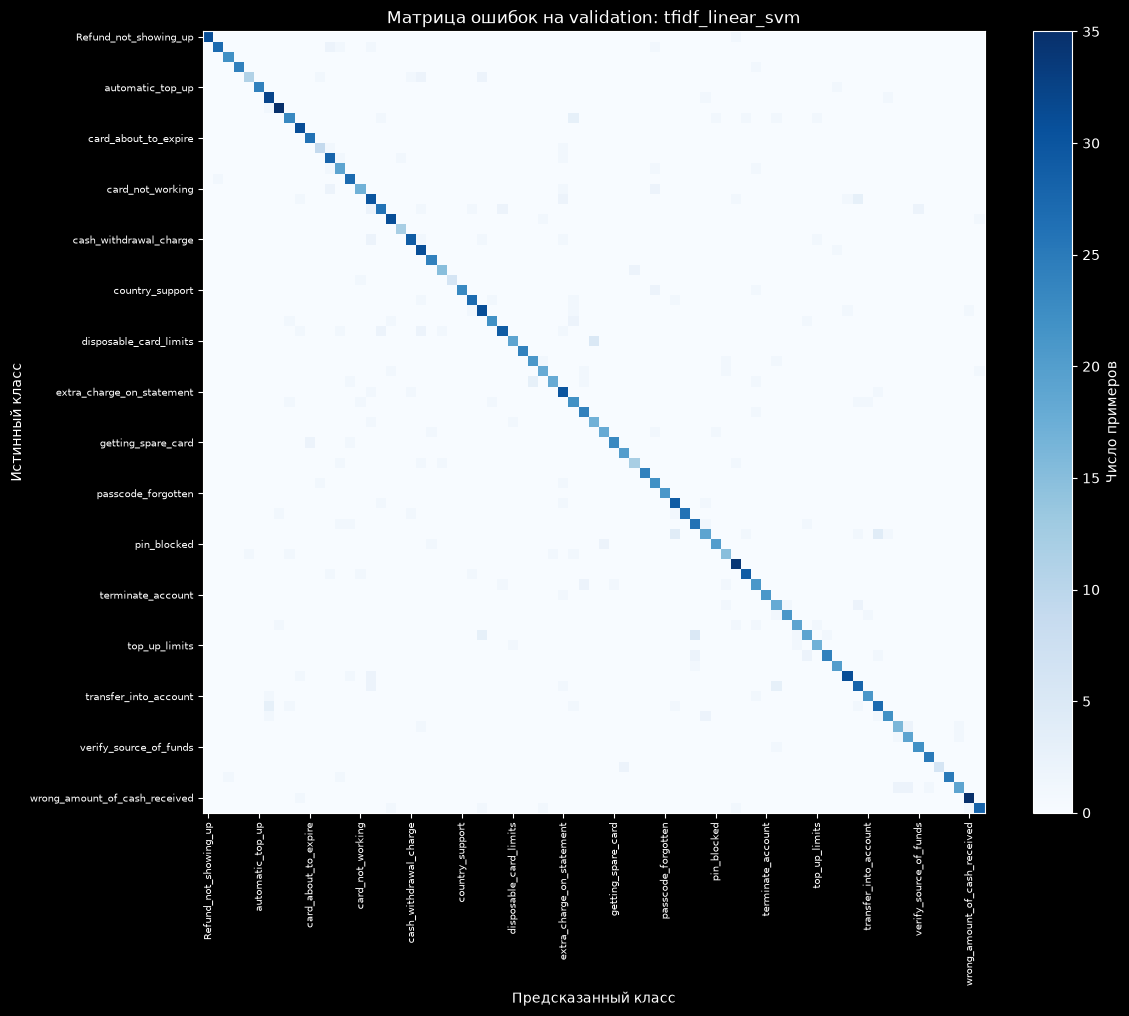

Матрица сохранена: C:\Users\maks5\Documents\Codex\2026-11-13\x20\experiments\baseline\notebook_best_model_confusion_matrix.png
Модели сохранены в: C:\Users\maks5\Documents\Codex\2026-11-13\x20\work\notebook_models
MLflow database: C:\Users\maks5\Documents\Codex\2026-11-13\x20\mlflow.db


In [7]:
matrix = confusion_matrix(y_val, best_pred, labels=labels)
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(matrix, interpolation='nearest', cmap='Blues')
ticks = np.arange(0, len(labels), 5)
ax.set_xticks(ticks, [labels[i] for i in ticks], rotation=90, fontsize=7)
ax.set_yticks(ticks, [labels[i] for i in ticks], fontsize=7)
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Истинный класс')
ax.set_title(f'Матрица ошибок на validation: {best_name}')
fig.colorbar(image, ax=ax, label='Число примеров')
fig.tight_layout()
matrix_path = OUT_DIR / 'notebook_best_model_confusion_matrix.png'
fig.savefig(matrix_path, dpi=160, bbox_inches='tight')
plt.show()
print(f'Матрица сохранена: {matrix_path}')
print(f'Модели сохранены в: {MODEL_DIR}')
print(f'MLflow database: {tracking_db}')